In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns
from scipy.stats import ttest_rel, wilcoxon
from scipy.stats import pearsonr

# load common plot configurations
import plot_config
session_colors = plot_config.session_colors

In [3]:
# Base directory
base_path = Path('/Users/liuq13/project-SPCD/beh_processed_subs/')

### Odor Prediction Accuracy Across Runs and Odors

Subjects were asked to learn to associate odors with conditioned stimuli in this odor prediction task.
- First, we examine the odor prediction data across the 3 runs, as well as across different odors (clean air, sweet, savory).  
- Ideally, all subjects should have learned to perform the task with high accuracy.  
- However, we may need to exclude those who did not reach a reasonable performance threshold.


In [4]:
all_run_stats = []
all_odor_stats = []

# Loop through each subject folder
for subj_folder in sorted(base_path.glob('sub-*')):
    file_path = subj_folder / 'odor_pred_dat.csv'
    if not file_path.exists():
        continue

    df = pd.read_csv(file_path)

    # Ensure numeric
    df['Run'] = pd.to_numeric(df['Run'], errors='coerce')
    df['acc'] = pd.to_numeric(df['acc'], errors='coerce')
    df['rt'] = pd.to_numeric(df['rt'], errors='coerce')
    df['odor_num'] = pd.to_numeric(df['odor_num'], errors='coerce')

    # Drop invalid rows
    df = df.dropna(subset=['Run', 'acc', 'odor_num'])

    # --- By Run ---
    stats_by_run = df.groupby('Run')[['acc', 'rt']].mean().reset_index()
    stats_by_run['subject'] = subj_folder.name
    stats_by_run.rename(columns={'acc': 'mean_acc', 'rt': 'mean_rt'}, inplace=True)
    stats_by_run = stats_by_run[['subject', 'Run', 'mean_acc', 'mean_rt']]
    all_run_stats.append(stats_by_run)

    # --- By Odor Number ---
    stats_by_odor = df.groupby('odor_num')[['acc', 'rt']].mean().reset_index()
    stats_by_odor['subject'] = subj_folder.name
    stats_by_odor.rename(columns={'acc': 'mean_acc', 'rt': 'mean_rt'}, inplace=True)
    stats_by_odor = stats_by_odor[['subject', 'odor_num', 'mean_acc', 'mean_rt']]
    all_odor_stats.append(stats_by_odor)

# Combine all subjects' results
run_result_df = pd.concat(all_run_stats, ignore_index=True)
odor_result_df = pd.concat(all_odor_stats, ignore_index=True)

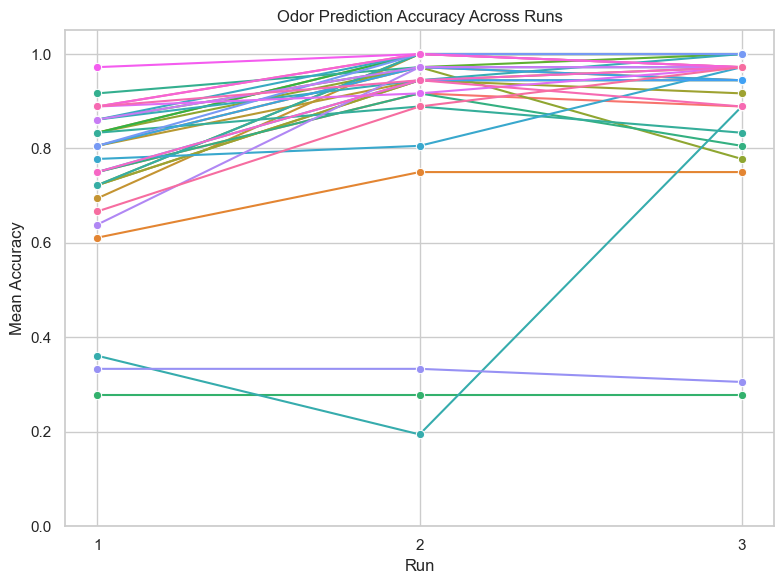

In [5]:
sns.set(style='whitegrid')

# Plot
plt.figure(figsize=(8, 6))
sns.lineplot(data=run_result_df, x='Run', y='mean_acc', hue='subject', marker='o', legend=False)

plt.title('Odor Prediction Accuracy Across Runs')
plt.xlabel('Run')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1.05)
plt.xticks(sorted(run_result_df['Run'].unique()))
plt.tight_layout()
plt.show()


### Exclusion of Low-Performing Participants

We found two participants who performed at or near chance level across all 3 runs in the odor prediction task.  
As a result, we decided to exclude these two participants from all following behavioral analyses.  
They will also be excluded from the fMRI data analysis to ensure consistency and data quality.


In [6]:
subj_max_acc = run_result_df.groupby('subject')['mean_acc'].max().reset_index()
chance_cutoff = 0.4
chance_subjects = subj_max_acc[subj_max_acc['mean_acc'] < chance_cutoff]['subject'].tolist()

Take a look at who are the two:

In [7]:
chance_subjects

['sub-19', 'sub-33']

Remove them from the odor prediction task data:

In [8]:
filtered_run_df = run_result_df[~run_result_df['subject'].isin(chance_subjects)]
filtered_odor_df = odor_result_df[~odor_result_df['subject'].isin(chance_subjects)]

In [9]:
filtered_run_df

,subject,Run,mean_acc,mean_rt
0,sub-01,1.0,0.888889,1.108406
1,sub-01,2.0,1.000000,1.015001
2,sub-01,3.0,1.000000,1.200450
3,sub-02,1.0,0.750000,1.684634
4,sub-02,2.0,0.916667,1.652291
...,...,...,...,...
97,sub-40,2.0,0.944444,1.294580
98,sub-40,3.0,0.888889,1.369288
99,sub-41,1.0,0.666667,1.453762
100,sub-41,2.0,0.888889,1.390376


## redraw the plot after excluding

/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/3190960306.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_run_df['Run_label'] = filtered_run_df['Run'].apply(lambda x: f"Run {int(x)}")


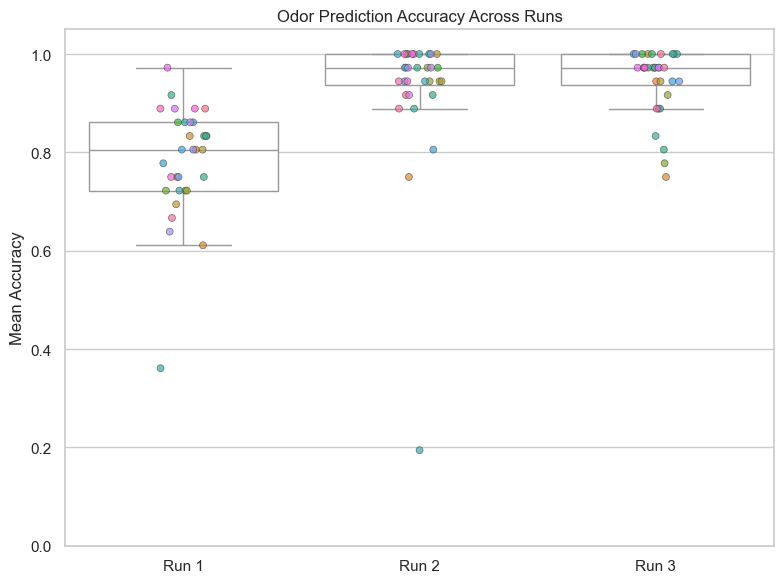

In [10]:
# Convert numeric Run to labeled string
filtered_run_df['Run_label'] = filtered_run_df['Run'].apply(lambda x: f"Run {int(x)}")

plt.figure(figsize=(8, 6))

# Boxplot of accuracy per run
sns.boxplot(data=filtered_run_df, x='Run_label', y='mean_acc',
            color='white', fliersize=0, linewidth=1)

# Jittered individual points per run
sns.stripplot(data=filtered_run_df, x='Run_label', y='mean_acc', hue='subject',
              dodge=False, jitter=True, alpha=0.7, marker='o', linewidth=0.5)

# Final plot settings
plt.title('Odor Prediction Accuracy Across Runs')
plt.xlabel('')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1.05)
plt.legend([], [], frameon=False)  # Hide crowded legend
plt.tight_layout()
plt.show()


### also drawing with mean, error bars

/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/2328377515.py:4: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


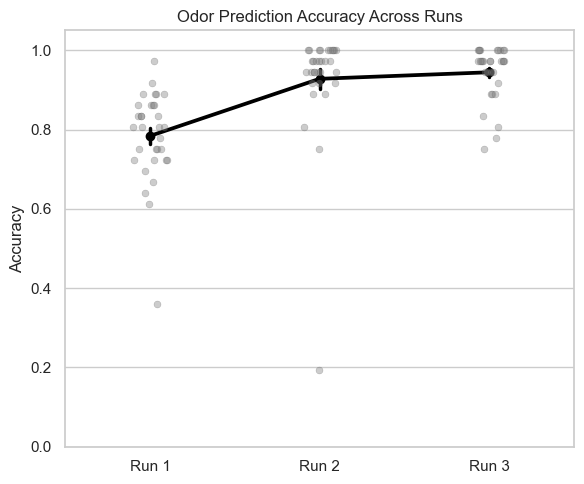

In [11]:
plt.figure(figsize=(6, 5))

# Jittered individual points (plotted first, in the background)
sns.stripplot(
    data=filtered_run_df, x='Run_label', y='mean_acc', color='gray',
    dodge=False, jitter=True, alpha=0.4, marker='o', linewidth=0.3, edgecolor='gray'
)

# Mean ± SE across runs, connected by line
sns.pointplot(
    data=filtered_run_df, x='Run_label', y='mean_acc',
    dodge=False, errorbar='se', markers='o', color='black',
    err_kws={'linewidth': 2.5}, markersize=5
)

# Final plot settings
plt.title('Odor Prediction Accuracy Across Runs')
plt.xlabel('')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)

# Hide crowded legend
plt.legend([], [], frameon=False)

plt.tight_layout()
plt.savefig('../plots/odor_pred.pdf', format='pdf', bbox_inches='tight')
plt.show()


### Additional Checks Before Probe Task Analysis

Before moving on to the probe task choices, we checked two aspects of the odor prediction task:

1. **Reaction Time (RT):**  
   We examined RT across runs to see if there were any systematic changes, but did not observe any interesting patterns.

2. **Prediction Type (Odors vs. Clean Air):**  
   We also explored whether participants learned the task differently depending on whether they were predicting odors or clean air.  
   Again, no clear or interesting pattern was found.

These checks provided no evidence of meaningful behavioral differences, so we proceeded with the probe task analysis.


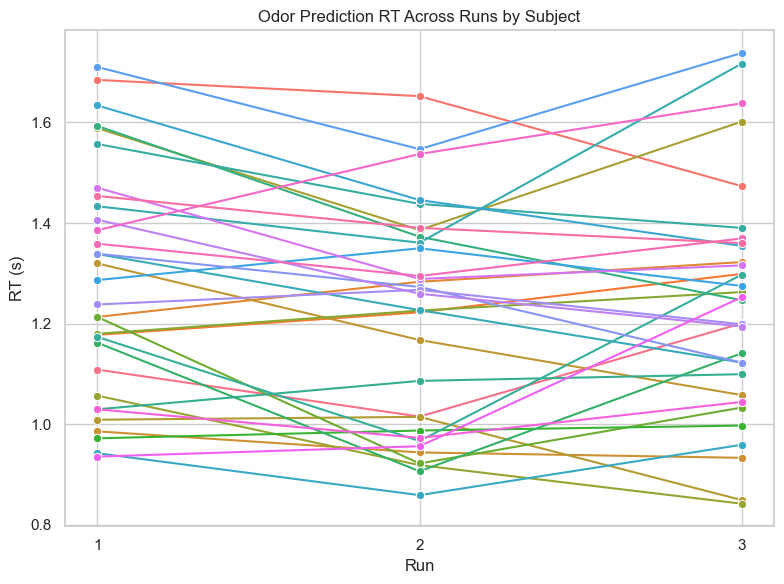

In [12]:
sns.set(style='whitegrid')

# Plot
plt.figure(figsize=(8, 6))
sns.lineplot(data=filtered_run_df, x='Run', y='mean_rt', hue='subject', marker='o', legend=False)

plt.title('Odor Prediction RT Across Runs by Subject')
plt.xlabel('Run')
plt.ylabel('RT (s)')
plt.xticks(sorted(df['Run'].unique()))
plt.tight_layout()
plt.show()

/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/1846270232.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_odor_df['odor_label'] = filtered_odor_df['odor_num'].map(odor_labels)
/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/1846270232.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_odor_df, x='odor_label', y='mean_acc', palette='Set2')
/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/1846270232.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's defini

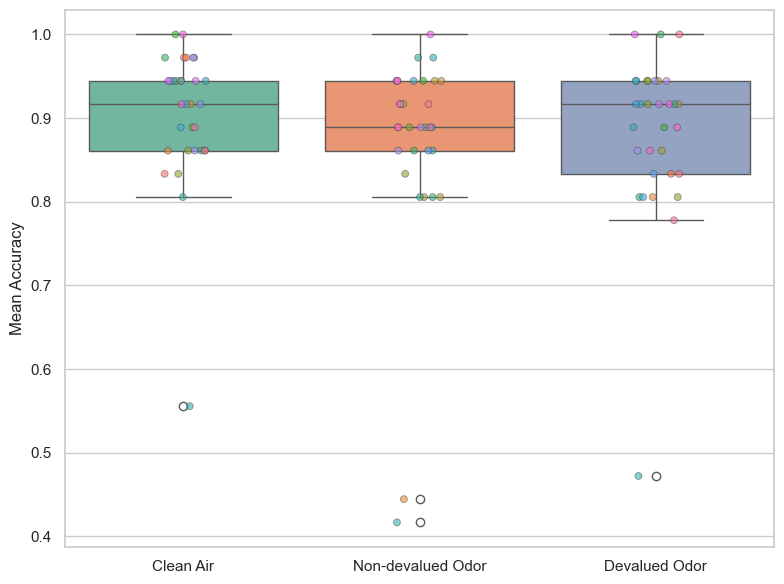

In [13]:
# Map odor_num to labels
odor_labels = {
    0: 'Clean Air',
    1: 'Non-devalued Odor',
    2: 'Devalued Odor'
}
filtered_odor_df['odor_label'] = filtered_odor_df['odor_num'].map(odor_labels)

# Plot
sns.set(style='whitegrid')
plt.figure(figsize=(8, 6))

# Boxplot of mean accuracy by odor label
sns.boxplot(data=filtered_odor_df, x='odor_label', y='mean_acc', palette='Set2')

# Add individual data points as jittered stripplot
sns.stripplot(data=filtered_odor_df, x='odor_label', y='mean_acc', 
              hue='subject', dodge=False, jitter=True, alpha=0.6, linewidth=0.5, edgecolor='gray', legend=False)

plt.xlabel('')
plt.ylabel('Mean Accuracy')
plt.tight_layout()
plt.show()


### Analysis: Pre vs Post Meal Probe Choice 

* This section analyzes probe choices made before and after the meal, excluding two participants who performed at or near chance level on the odor prediction task.
* We focus on choice proportions for specific cue pairs of interest, comparing them across the pre- and post-meal phases.
* In particular, we examine choices among the preconditioned cues (A1, A2, A3) and the conditioned cues (B1, B2, B3). Notably, B2 was associated with the devalued odor.

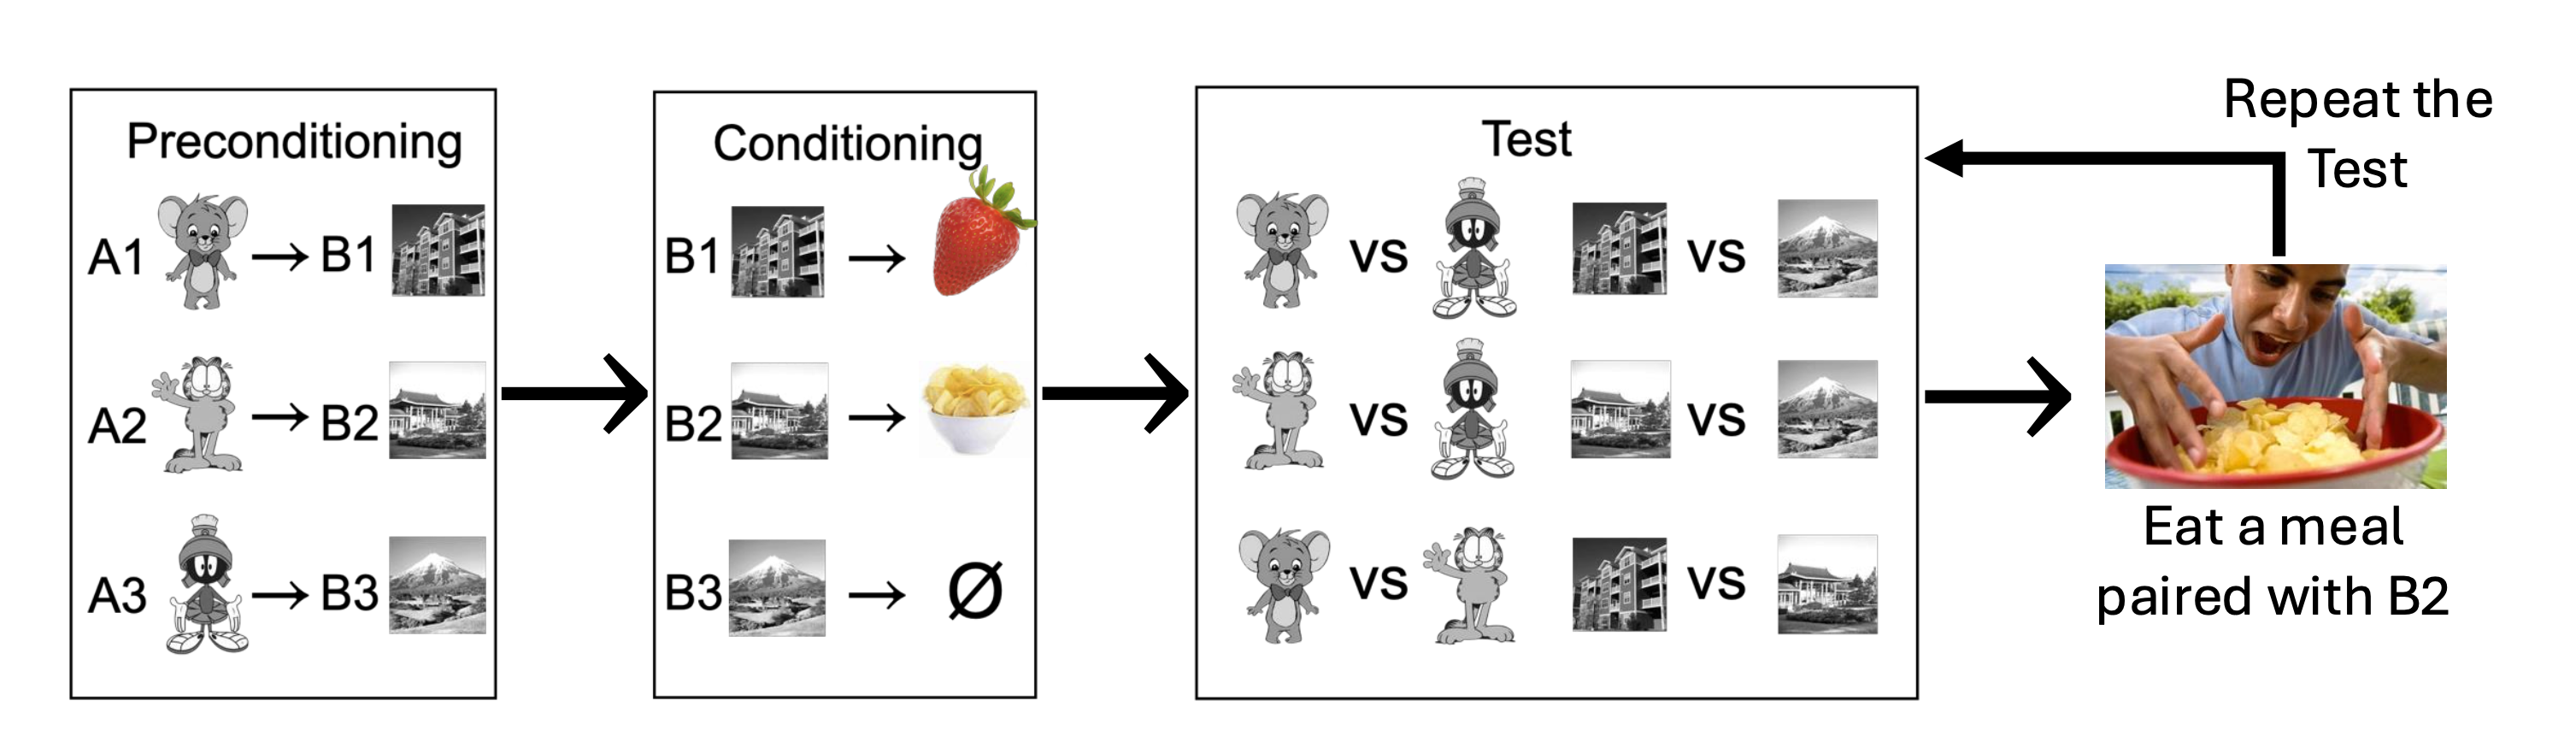

In [14]:
display(Image(filename='diagram.png'))

In [15]:
# Collect pre/post data
pre_records = []
post_records = []

# Loop through subjects
for subj_folder in sorted(base_path.glob('sub-*')):
    subj = subj_folder.name

    if subj in chance_subjects:
        continue  # skip subjects performing at chance level

    # --- Pre-meal ---
    pre_path = subj_folder / 'pre_meal_dat.csv'
    if pre_path.exists():
        df_pre = pd.read_csv(pre_path)
        
        # drop rows missing key fields
        df_pre = df_pre.dropna(subset=['choice_class', 'acc', 'rt'])

        # aggregate accuracy & RT by choice_class
        pre = (
            df_pre
            .groupby('choice_class')
            .agg(
                acc=('acc', 'mean'),
                rt=('rt', 'mean')
            )
            .reset_index()
        )
        
        pre['subject'] = subj
        pre['phase'] = 'pre'
        pre_records.append(pre)

    # --- Post-meal ---
    post_path = subj_folder / 'post_meal_dat.csv'
    if post_path.exists():
        df_post = pd.read_csv(post_path)

        # drop rows missing key fields
        df_post = df_post.dropna(subset=['choice_class', 'acc', 'rt'])

        # aggregate accuracy & RT by choice_class
        post = (
            df_post
            .groupby('choice_class')
            .agg(
                acc=('acc', 'mean'),
                rt=('rt', 'mean')
            )
            .reset_index()
        )

        post['subject'] = subj
        post['phase'] = 'post'
        post_records.append(post)

# Combine all
df_all = pd.concat(pre_records + post_records, ignore_index=True)
df_all

,choice_class,acc,rt,subject,phase
0,A1>A2,0.083333,0.698633,sub-01,pre
1,A1>A3,0.083333,0.508827,sub-01,pre
2,A2>A3,0.083333,0.710682,sub-01,pre
3,B1>B2,0.272727,0.588570,sub-01,pre
4,B1>B3,0.000000,0.518104,sub-01,pre
...,...,...,...,...,...
379,A1>A3,0.000000,0.613342,sub-41,post
380,A2>A3,0.090909,0.629265,sub-41,post
381,B1>B2,0.900000,0.815376,sub-41,post
382,B1>B3,0.090909,0.656021,sub-41,post


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/843211760.py:8: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df_all, x='choice_class', y='acc', hue='phase',


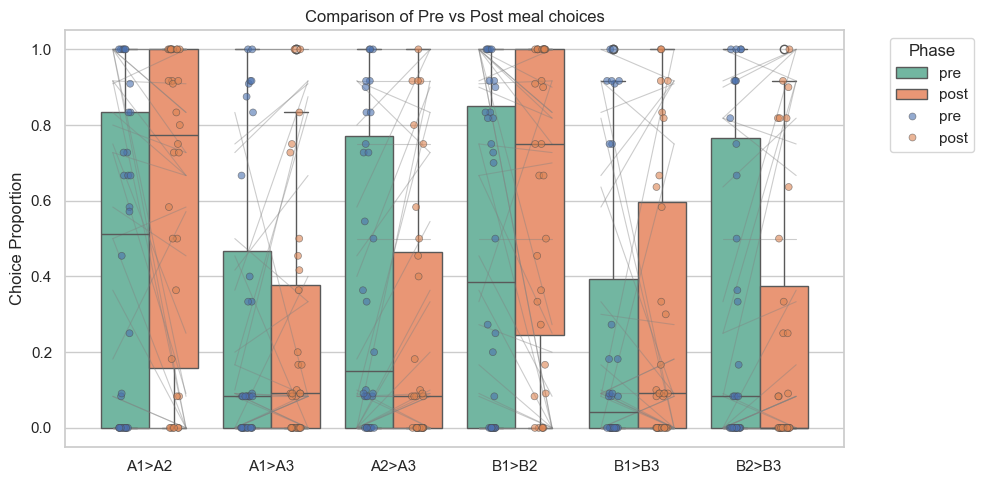

In [16]:
# Make numeric labels for choice_class
unique_classes = sorted(df_all['choice_class'].unique())
class_to_num = {label: i for i, label in enumerate(unique_classes)}

# Plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_all, x='choice_class', y='acc', hue='phase', palette='Set2')
sns.stripplot(data=df_all, x='choice_class', y='acc', hue='phase',
              dodge=True, jitter=True, alpha=0.6, linewidth=0.5, edgecolor='gray')

# Draw connecting lines
for (subj, cls), group in df_all.groupby(['subject', 'choice_class']):
    if group.shape[0] == 2:  # Must have both pre and post
        base_x = class_to_num[cls]
        x_vals = [base_x - 0.3, base_x + 0.3]  # Pre and post offset
        y_vals = group.sort_values('phase')['acc'].tolist()
        plt.plot(x_vals, y_vals, color='gray', alpha=0.4, linewidth=0.8)

# Final touches
plt.title('Comparison of Pre vs Post meal choices')
plt.xlabel('')
plt.ylabel('Choice Proportion')
plt.ylim(-0.05, 1.05)
plt.legend(title='Phase', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/1910310715.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


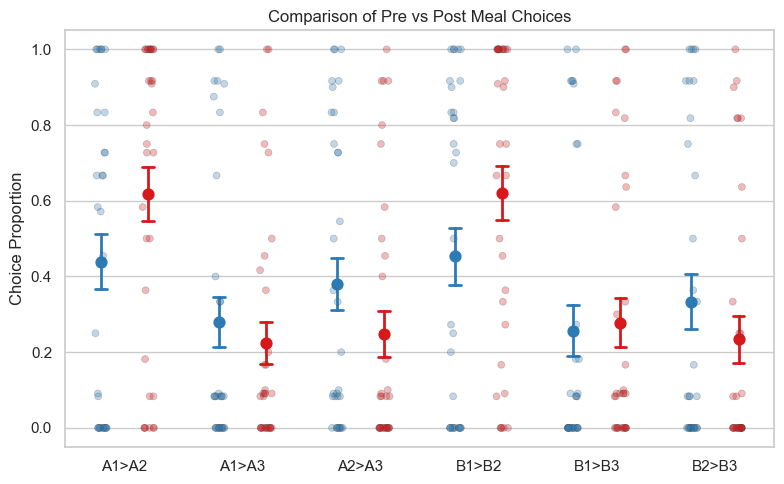

In [17]:
# Make numeric labels for choice_class
unique_classes = sorted(df_all['choice_class'].unique())
class_to_num = {label: i for i, label in enumerate(unique_classes)}

# Plot
plt.figure(figsize=(8, 5))

# Mean ± SE bar with pointplot
sns.pointplot(
    data=df_all, x='choice_class', y='acc', hue='phase',
    errorbar='se', dodge=0.4, palette=session_colors,
    markers='o', linestyles='none', err_kws={'linewidth': 2}, 
    capsize=0.1
)

# Stripplot overlaid (individual data points)
sns.stripplot(
    data=df_all, x='choice_class', y='acc', hue='phase',
    dodge=True, jitter=True, alpha=0.3, linewidth=0.5, edgecolor='gray',
    palette=session_colors
)

# Final touches
plt.title('Comparison of Pre vs Post Meal Choices')
plt.xlabel('')
plt.ylabel('Choice Proportion')
plt.ylim(-0.05, 1.05)

# Remove legend
plt.gca().get_legend().remove()
#plt.legend(title='Phase', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../plots/probe.pdf', format='pdf', bbox_inches='tight')
plt.show()


### Comparison of reaction time

In [83]:
df_all

,choice_class,acc,rt,subject,phase,pair_group,AB_set
0,A1>A2,0.083333,0.698633,sub-01,pre,Pair12,A set
1,A1>A3,0.083333,0.508827,sub-01,pre,Pair13,A set
2,A2>A3,0.083333,0.710682,sub-01,pre,Pair23,A set
3,B1>B2,0.272727,0.588570,sub-01,pre,Pair12,B set
4,B1>B3,0.000000,0.518104,sub-01,pre,Pair13,B set
...,...,...,...,...,...,...,...
379,A1>A3,0.000000,0.613342,sub-41,post,Pair13,A set
380,A2>A3,0.090909,0.629265,sub-41,post,Pair23,A set
381,B1>B2,0.900000,0.815376,sub-41,post,Pair12,B set
382,B1>B3,0.090909,0.656021,sub-41,post,Pair13,B set


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/676366548.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


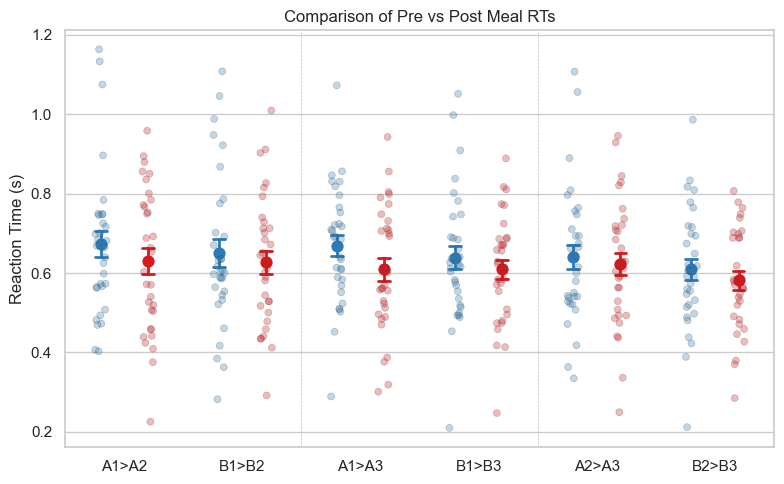

In [18]:
pair_order = ['A1>A2', 'B1>B2',
              'A1>A3', 'B1>B3',
              'A2>A3', 'B2>B3']

plt.figure(figsize=(8, 5))

sns.pointplot(
    data=df_all, x='choice_class', y='rt', hue='phase',
    order=pair_order,                 
    errorbar='se', dodge=0.4, palette=session_colors,
    markers='o', linestyles='none',
    err_kws={'linewidth': 2}, capsize=0.1,
)

sns.stripplot(
    data=df_all, x='choice_class', y='rt', hue='phase',
    order=pair_order,                
    dodge=True, jitter=True, alpha=0.3,
    linewidth=0.5, edgecolor='gray',
    palette=session_colors,
)

plt.title('Comparison of Pre vs Post Meal RTs')
plt.xlabel('')
plt.ylabel('Reaction Time (s)')

# optional: add light vertical lines between the three logical pairs
for x in [1.5, 3.5]:
    plt.axvline(x, linestyle='--', linewidth=0.5, color='gray', alpha=0.5)

plt.gca().get_legend().remove()
plt.tight_layout()
plt.savefig('../plots/probe_rt.pdf', format='pdf', bbox_inches='tight')
plt.show()


### Collapse multiple A pairs and B pairs

In [19]:
# Label A-set vs B-set
def ab_group(x):
    if x.startswith('A'):
        return 'A set'
    elif x.startswith('B'):
        return 'B set'
    return None

df_ab = df_all.copy()
df_ab['AB_set'] = df_ab['choice_class'].apply(ab_group)

# Keep only valid rows
df_ab = df_ab.dropna(subset=['AB_set'])

df_ab_summary = (
    df_ab
    .groupby(['subject', 'phase', 'AB_set'], as_index=False)
    .agg(rt=('rt', 'mean'))
)

# Reorder phase to pre → post
df_ab_summary['phase'] = pd.Categorical(
    df_ab_summary['phase'],
    categories=['pre', 'post'],
    ordered=True
)

In [20]:
df_ab_summary

,subject,phase,AB_set,rt
0,sub-01,post,A set,0.468590
1,sub-01,post,B set,0.543167
2,sub-01,pre,A set,0.639381
3,sub-01,pre,B set,0.565614
4,sub-02,post,A set,0.663431
...,...,...,...,...
123,sub-40,pre,B set,0.652549
124,sub-41,post,A set,0.669815
125,sub-41,post,B set,0.759452
126,sub-41,pre,A set,0.689419


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/2637959077.py:11: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


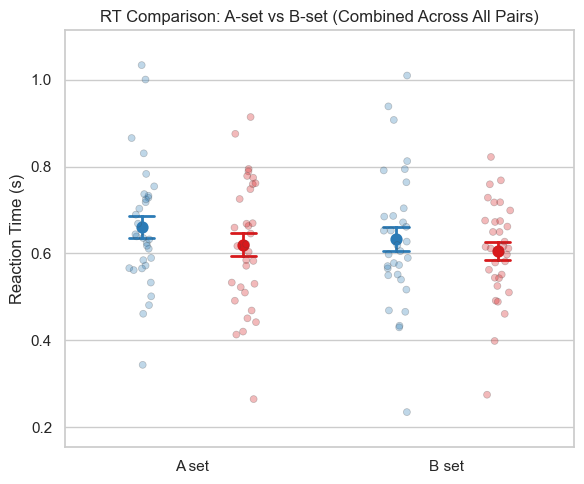

In [21]:
plt.figure(figsize=(6, 5))

sns.pointplot(
    data=df_ab_summary, x='AB_set', y='rt', hue='phase',
    order=['A set', 'B set'],
    errorbar='se', dodge=0.4, palette=session_colors,
    markers='o', linestyles='none',
    err_kws={'linewidth': 2}, capsize=0.1,
)

sns.stripplot(
    data=df_ab_summary, x='AB_set', y='rt', hue='phase',
    order=['A set', 'B set'],
    dodge=True, jitter=True, alpha=0.3,
    linewidth=0.5, edgecolor='gray',
    palette=session_colors,
)

plt.title('RT Comparison: A-set vs B-set (Combined Across All Pairs)')
plt.xlabel('')
plt.ylabel('Reaction Time (s)')

# optional padding
rt_min = df_ab_summary['rt'].min()
rt_max = df_ab_summary['rt'].max()
pad = 0.1 * (rt_max - rt_min)
plt.ylim(rt_min - pad, rt_max + pad)

plt.gca().get_legend().remove()
plt.tight_layout()

plt.savefig('../plots/probe_rt_A_vs_B.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [88]:
import statsmodels.formula.api as smf

# Ensure categorical coding
df_ab_summary['AB_set'] = df_ab_summary['AB_set'].astype('category')
df_ab_summary['phase'] = df_ab_summary['phase'].astype('category')

model = smf.mixedlm(
    "rt ~ AB_set * phase",
    data=df_ab_summary,
    groups=df_ab_summary["subject"],
)
result = model.fit()
print(result.summary())


                 Mixed Linear Model Regression Results
Model:                  MixedLM       Dependent Variable:       rt      
No. Observations:       128           Method:                   REML    
No. Groups:             32            Scale:                    0.0041  
Min. group size:        4             Log-Likelihood:           114.4771
Max. group size:        4             Converged:                Yes     
Mean group size:        4.0                                             
------------------------------------------------------------------------
                              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------
Intercept                      0.661    0.025 26.281 0.000  0.611  0.710
AB_set[T.B set]               -0.028    0.016 -1.731 0.083 -0.059  0.004
phase[T.post]                 -0.040    0.016 -2.504 0.012 -0.071 -0.009
AB_set[T.B set]:phase[T.post]  0.013    0.023  0.578 0.563 -0.031  0.

## Mixed-Effects Model Summary (A-set vs B-set Aggregated RTs)

A linear mixed-effects model examined reaction times (RTs) across **A-set vs B-set** choices and **pre- vs post-meal** phases, including random intercepts for subjects.

### Main Results

- **Post-meal responses were significantly faster**  
  - *phase (post vs pre):* **β = –0.040**, *p = .012*  
  - → Participants sped up by ~40 ms after the meal.

- **No significant RT difference between A-set and B-set**  
  - *AB_set (B vs A):* β = –0.028, *p = .083*  
  - → B-set was slightly faster, but not reliably so.

- **No Set × Phase interaction**  
  - *AB_set × phase:* β = +0.013, *p = .563*  
  - → The post-meal speeding was similar for A-set and B-set.

### Interpretation

**Participants responded faster after the meal, but there were no meaningful RT differences between A-set and B-set choices, and the meal manipulation affected both sets similarly.**


In [89]:
pair_map = {
    'A1>A2': 'Pair12',
    'B1>B2': 'Pair12',
    'A1>A3': 'Pair13',
    'B1>B3': 'Pair13',
    'A2>A3': 'Pair23',
    'B2>B3': 'Pair23',
}

df_all['pair_group'] = df_all['choice_class'].map(pair_map)

df_all['AB_set'] = df_all['choice_class'].apply(lambda x: 'A set' if x.startswith('A') else 'B set')
df_all['phase'] = pd.Categorical(df_all['phase'], categories=['pre', 'post'], ordered=True)

import statsmodels.formula.api as smf

pairs = ['Pair12', 'Pair13', 'Pair23']

for p in pairs:
    print(f"\n====== {p} ======\n")
    df_p = df_all[df_all['pair_group'] == p].copy()

    # Fit mixed model
    model = smf.mixedlm(
        "rt ~ AB_set * phase",
        data=df_p,
        groups=df_p["subject"]
    )
    result = model.fit()
    print(result.summary())



====== Pair12 ======

                 Mixed Linear Model Regression Results
Model:                   MixedLM       Dependent Variable:       rt     
No. Observations:        128           Method:                   REML   
No. Groups:              32            Scale:                    0.0121 
Min. group size:         4             Log-Likelihood:           58.5396
Max. group size:         4             Converged:                Yes    
Mean group size:         4.0                                            
------------------------------------------------------------------------
                              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------
Intercept                      0.673    0.032 20.802 0.000  0.609  0.736
AB_set[T.B set]               -0.022    0.027 -0.801 0.423 -0.076  0.032
phase[T.post]                 -0.042    0.027 -1.535 0.125 -0.096  0.012
AB_set[T.B set]:phase[T.post]  0.019    0.039 

### check out per run stats

In [22]:
# Collect pre/post data
pre_records = []
post_records = []

# Loop through subjects
for subj_folder in sorted(base_path.glob('sub-*')):
    subj = subj_folder.name

    if subj in chance_subjects:
        continue  # skip subjects performing at chance level

    # ---------- Pre-meal ----------
    pre_path = subj_folder / 'pre_meal_dat.csv'
    if pre_path.exists():
        df_pre = pd.read_csv(pre_path)

        # drop rows missing key fields
        df_pre = df_pre.dropna(subset=['choice_class', 'acc', 'rt', 'Run'])

        # aggregate accuracy & RT by run and choice_class
        pre = (
            df_pre
            .groupby(['Run', 'choice_class'])
            .agg(
                acc=('acc', 'mean'),
                rt=('rt', 'mean')
            )
            .reset_index()
        )

        pre['subject'] = subj
        pre['phase'] = 'pre'
        pre_records.append(pre)

    # ---------- Post-meal ----------
    post_path = subj_folder / 'post_meal_dat.csv'
    if post_path.exists():
        df_post = pd.read_csv(post_path)

        # drop rows missing key fields
        df_post = df_post.dropna(subset=['choice_class', 'acc', 'rt', 'Run'])

        # aggregate accuracy & RT by run and choice_class
        post = (
            df_post
            .groupby(['Run', 'choice_class'])
            .agg(
                acc=('acc', 'mean'),
                rt=('rt', 'mean')
            )
            .reset_index()
        )

        post['subject'] = subj
        post['phase'] = 'post'
        post_records.append(post)

# Combine all
df_all = pd.concat(pre_records + post_records, ignore_index=True)

# (optional) make Run a cleaner integer and/or rename
df_all['Run'] = df_all['Run'].astype(int)
df_all = df_all.rename(columns={'Run': 'run'})

df_all


,run,choice_class,acc,rt,subject,phase
0,1,A1>A2,0.00,0.887381,sub-01,pre
1,1,A1>A3,0.25,0.676318,sub-01,pre
2,1,A2>A3,0.25,0.843897,sub-01,pre
3,1,B1>B2,0.25,0.776898,sub-01,pre
4,1,B1>B3,0.00,0.637122,sub-01,pre
...,...,...,...,...,...,...
1147,3,A1>A3,0.00,0.426971,sub-41,post
1148,3,A2>A3,0.00,0.683825,sub-41,post
1149,3,B1>B2,1.00,0.937495,sub-41,post
1150,3,B1>B3,0.00,0.735540,sub-41,post


In [23]:
# --- Label A-set vs B-set ---
def ab_group(x):
    if isinstance(x, str) and x.startswith('A'):
        return 'A set'
    elif isinstance(x, str) and x.startswith('B'):
        return 'B set'
    return None

df_ab = df_all.copy()
df_ab['AB_set'] = df_ab['choice_class'].apply(ab_group)

# Keep only rows with valid A/B set labels
df_ab = df_ab.dropna(subset=['AB_set'])

# Make sure Run is an integer
df_ab['run'] = df_ab['run'].astype(int)

# --- Collapse within A-set and B-set, but KEEP RUN ---
df_ab_runs = (
    df_ab
    .groupby(['subject', 'phase', 'run', 'AB_set'], as_index=False)
    .agg(rt=('rt', 'mean'))
)

# Order phase → pre then post
df_ab_runs['phase'] = pd.Categorical(
    df_ab_runs['phase'],
    categories=['pre', 'post'],
    ordered=True
)

df_ab_runs


,subject,phase,run,AB_set,rt
0,sub-01,post,1,A set,0.494581
1,sub-01,post,1,B set,0.521236
2,sub-01,post,2,A set,0.468166
3,sub-01,post,2,B set,0.518770
4,sub-01,post,3,A set,0.443024
...,...,...,...,...,...
379,sub-41,pre,1,B set,0.936502
380,sub-41,pre,2,A set,0.671418
381,sub-41,pre,2,B set,0.565883
382,sub-41,pre,3,A set,0.778669


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/1029199499.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_54742/1029199499.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


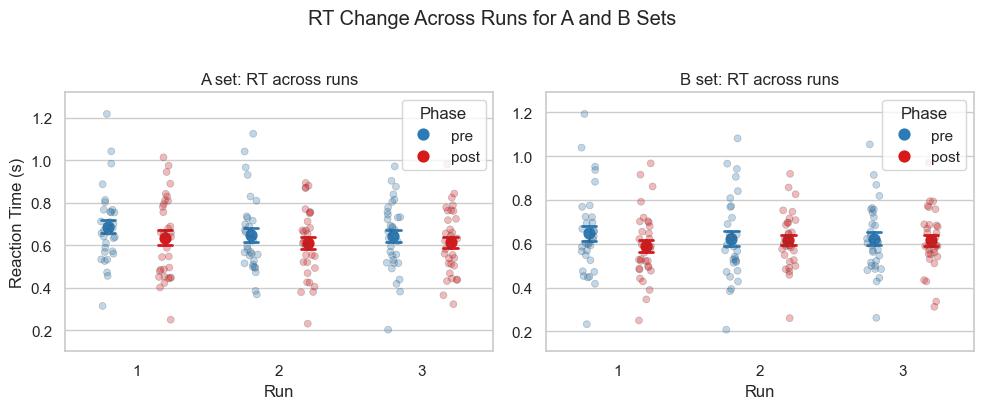

In [24]:
# Make sure run is ordered nicely
df_ab_runs = df_ab_runs.copy()
df_ab_runs['run'] = df_ab_runs['run'].astype(int)

ab_order = ['A set', 'B set']

plt.figure(figsize=(10, 4))

for i, ab in enumerate(ab_order, start=1):
    ax = plt.subplot(1, 2, i)

    sub = df_ab_runs[df_ab_runs['AB_set'] == ab]

    # Pointplot: mean ± SE per run, pre vs post
    sns.pointplot(
        data=sub, x='run', y='rt', hue='phase',
        errorbar='se', dodge=0.4, palette=session_colors,
        markers='o', linestyles='none',
        err_kws={'linewidth': 2}, capsize=0.1,
        ax=ax
    )

    # Stripplot: show subject data
    sns.stripplot(
        data=sub, x='run', y='rt', hue='phase',
        dodge=True, jitter=True, alpha=0.3,
        linewidth=0.5, edgecolor='gray',
        palette=session_colors,
        ax=ax
    )

    ax.set_title(f'{ab}: RT across runs')
    ax.set_xlabel('Run')
    ax.set_ylabel('Reaction Time (s)' if i == 1 else '')

    # y-limits with padding (reuse your logic)
    rt_min = sub['rt'].min()
    rt_max = sub['rt'].max()
    pad = 0.1 * (rt_max - rt_min)
    ax.set_ylim(rt_min - pad, rt_max + pad)

    # Remove duplicate legends from the second layer
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[:2], labels[:2], title='Phase')

plt.suptitle('RT Change Across Runs for A and B Sets', y=1.02)
plt.tight_layout()

plt.savefig('../plots/probe_rt_runs_A_B.pdf', format='pdf', bbox_inches='tight')
plt.show()


### Save probe data & do stat testing

In [36]:
# Pivot to wide format (pre, post)
pivoted = df_all.pivot_table(index=['subject', 'choice_class'], columns='phase', values='acc').reset_index()
pivoted['change'] = pivoted['post'] - pivoted['pre']

In [18]:
# save pivoted df to drive
output_file = base_path / 'probe_choice_behavior_all.csv'

# Save the DataFrame
pivoted.to_csv(output_file, index=False)

In [19]:
# Perform statistical test per choice_class
print("Statistical Comparison (Post vs Pre):\n")
for cls in pivoted['choice_class'].unique():
    subset = pivoted[pivoted['choice_class'] == cls].dropna(subset=['pre', 'post'])

    if subset.shape[0] < 3:
        print(f"{cls}: not enough data (n={subset.shape[0]})")
        continue

    try:
        stat, p = wilcoxon(subset['post'], subset['pre'])
        print(f"{cls}: Wilcoxon signed-rank test: p = {p:.4f}")
    except ValueError as e:
        print(f"{cls}: Error - {str(e)}")


Statistical Comparison (Post vs Pre):

A1>A2: Wilcoxon signed-rank test: p = 0.0014
A1>A3: Wilcoxon signed-rank test: p = 0.1424
A2>A3: Wilcoxon signed-rank test: p = 0.0045
B1>B2: Wilcoxon signed-rank test: p = 0.0020
B1>B3: Wilcoxon signed-rank test: p = 0.5291
B2>B3: Wilcoxon signed-rank test: p = 0.0192


### Statistical Comparison: Post‐ vs Pre‐Meal Choices  

**Wilcoxon signed‐rank tests** were performed for each choice class to compare choice proportions before and after the meal. 
**Key takeaways**:
- Significant shifts were observed for **A1>A2**, **A2>A3**, **B1>B2**, and **B2>B3**.
- **A1>A3** and **B1>B3** did not show significant changes.

This demonstrates sensory-specific devaluation and model-based inference: participants not only reduced choices for the devalued cue (B2) but also for its associated preconditioned cue (A2). The significant changes in choice behavior before and after the meal support the hypothesis that participants used their internal model of cue–cue and cue-outcome associations to update preferences.

### Correlation Between Preconditioned (A) and Conditioned (B) Cue Choices

We examined whether participants made consistent choices between preconditioned (A) cues and their associated conditioned (B) cues, both before and after the meal. For each phase, we computed Pearson correlations across subjects for matched A–B cue pairs.

#### Key Finding:
Across all matched pairs, A and B choice proportions were **highly correlated** in both the pre- and post-meal phases (all r > 0.82, p < 1e-8). This indicates that participants consistently used the A→B associations to guide their decisions, and that **the structure of this learned relationship remained intact even after B2 was devalued**.


In [20]:
# Define matching A-B pairs (use your actual experimental mapping)
a_pairs = ['A1>A2', 'A2>A3', 'A1>A3']
b_pairs = ['B1>B2', 'B2>B3', 'B1>B3']

results = []

# For each phase (pre, post), compute correlation between A and B choices
for phase in ['pre', 'post']:
    phase_df = df_all[df_all['phase'] == phase]

    # Pivot: rows = subjects, columns = choice_class
    wide_df = phase_df.pivot(index='subject', columns='choice_class', values='acc')

    # Drop rows with missing data in any of the relevant columns
    paired_df = wide_df[a_pairs + b_pairs].dropna()

    # Compute correlation between each A-B pair
    for a, b in zip(a_pairs, b_pairs):
        r, p = pearsonr(paired_df[a], paired_df[b])
        results.append({
            'phase': phase,
            'A_choice': a,
            'B_choice': b,
            'correlation': r,
            'p_value': p
        })

# Turn into a dataframe
corr_results = pd.DataFrame(results)
print(corr_results)


  phase A_choice B_choice  correlation       p_value
0   pre    A1>A2    B1>B2     0.951915  5.844765e-17
1   pre    A2>A3    B2>B3     0.922682  5.959256e-14
2   pre    A1>A3    B1>B3     0.910470  4.947492e-13
3  post    A1>A2    B1>B2     0.951051  7.592512e-17
4  post    A2>A3    B2>B3     0.956969  1.142993e-17
5  post    A1>A3    B1>B3     0.827910  5.028236e-09


### Change in Choice Accuracy from Pre to Post Meal

To quantify the effect of meal-induced devaluation on behavior, we calculated the change in choice accuracy for each `choice_class` by subtracting pre-meal accuracy from post-meal accuracy (`Δ Proportion = Post - Pre`).


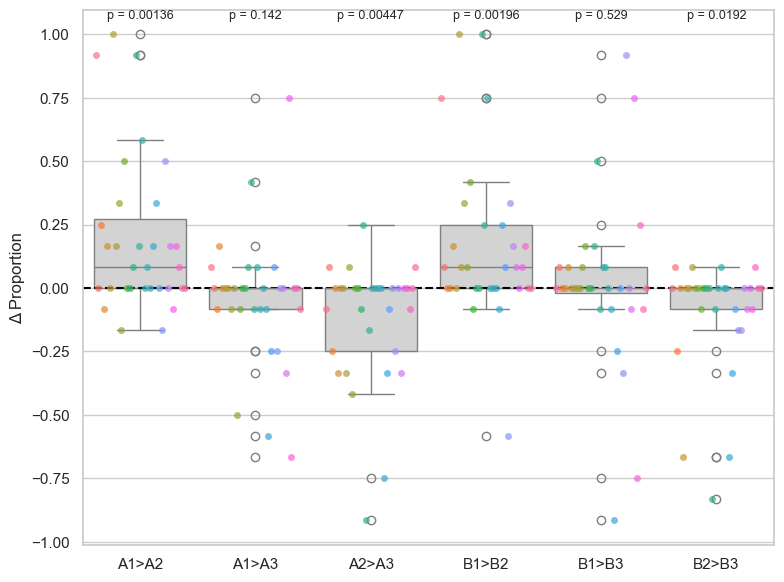

In [21]:
# Create the base plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=pivoted, x='choice_class', y='change', color='lightgray')
sns.stripplot(data=pivoted, x='choice_class', y='change', hue='subject', jitter=True, alpha=0.7, dodge=True)

# Add horizontal line at 0
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('')
plt.ylabel('Δ Proportion')

# Hide legend for clarity
plt.legend([], [], frameon=False)

# Perform Wilcoxon test and annotate
choice_classes = pivoted['choice_class'].unique()
y_max = pivoted['change'].max()

for i, cc in enumerate(choice_classes):
    vals = pivoted[pivoted['choice_class'] == cc]['change'].dropna()
    if len(vals) > 1 and not all(vals == 0):  # Wilcoxon requires at least 2 values and not all zero
        try:
            stat, p = wilcoxon(vals)
            plt.text(i, y_max + 0.05, f'p = {p:.3g}', ha='center', va='bottom', fontsize=9)
        except ValueError:
            plt.text(i, y_max + 0.05, f'NA', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


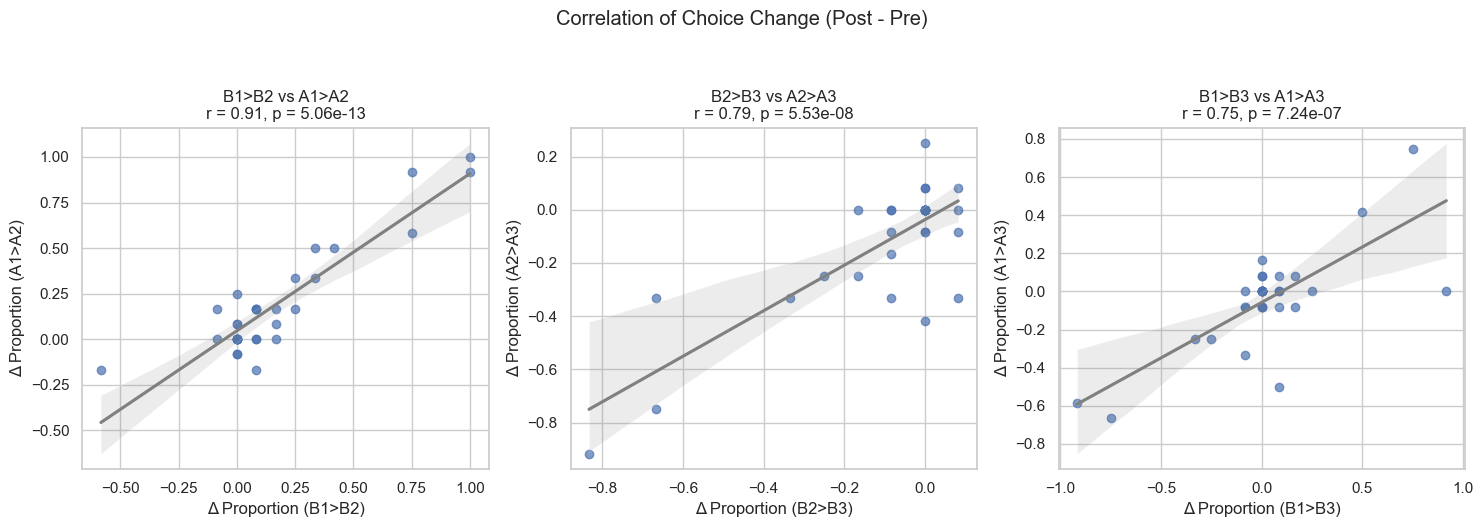

In [22]:
# Include the new pair in relevant_pairs
relevant_pairs = ['B1>B2', 'A1>A2', 'B2>B3', 'A2>A3', 'B1>B3', 'A1>A3']
filtered = pivoted[pivoted['choice_class'].isin(relevant_pairs)]
wide_change = filtered.pivot(index='subject', columns='choice_class', values='change').dropna()

# Set up 3-panel figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Define each pair
pairs = [
    ('B1>B2', 'A1>A2'),
    ('B2>B3', 'A2>A3'),
    ('B1>B3', 'A1>A3')
]

# Plot each pair
for i, (bx, ax_) in enumerate(pairs):
    x, y = wide_change[bx], wide_change[ax_]
    r, p = pearsonr(x, y)
    sns.regplot(x=x, y=y, ax=axes[i], scatter_kws={'alpha': 0.7}, line_kws={'color': 'gray'})
    axes[i].set_title(f'{bx} vs {ax_}\nr = {r:.2f}, p = {p:.3g}')
    axes[i].set_xlabel(f'Δ Proportion ({bx})')
    axes[i].set_ylabel(f'Δ Proportion ({ax_})')

plt.suptitle('Correlation of Choice Change (Post - Pre)', y=1.05)
plt.tight_layout()
plt.show()


### Summary of Choice Change Analysis

To examine the impact of meal-induced devaluation on odor preference behavior, we analyzed changes in choice accuracy (post-meal minus pre-meal) across multiple odor comparison conditions.

#### 1. Within-Condition Change
We performed Wilcoxon signed-rank tests to assess whether the change in choice proportion significantly differed from zero for each odor pair. Significant effects were observed for several comparisons, consistent with what we saw earlier.

#### 2. Cross-Condition Correlations
We tested whether individual changes in sweet (B) and savory (A) odor choices were correlated. For three matched A–B pairs:
- `B1>B2` vs `A1>A2`
- `B2>B3` vs `A2>A3`
- `B1>B3` vs `A1>A3`

Strong positive correlations were found across all three pairs (all *r* > 0.75, *p* < 1e-6), indicating that participants updated their choices similarly for conditioned cues relative to preconditioned cues.
